# Bagging from scratch — NumPy only, checked against scikit-learn

This notebook builds bagging out of plain NumPy, one README step at a time, and checks every step against
scikit-learn's `BaggingRegressor` / `BaggingClassifier`. The theory is in [`../README.md`](../README.md); the library
tour is in [`bagging_lab.ipynb`](bagging_lab.ipynb).

**How to use it:** run the imports cell first; then top-to-bottom always works. Each section restates the step (with
the README section it comes from), gives the code, then a small **check**. Boxes titled **Implementation hurdle** show a
real problem you hit when you write this yourself — each one is *demonstrated*, not just stated. Look at the output
and guess before reading the "How to read this" box.

**Rules:** NumPy implements the algorithm. scikit-learn is used only for `train_test_split`, `make_moons`, metrics,
and as the library model we compare against. All data is bundled (`data/*.csv`, written by `bagging_lab.ipynb`) or
generated — no internet needed.

### Theory → code map

| README section / equation | Function | Notebook section |
|---|---|---|
| §2.1 a regression tree picks the split with the smallest squared error | `find_best_split_naive`, `find_best_split_mse` | 1 |
| §2.1 grow the tree split by split; leaf = (weighted) mean | `fit_tree`, `apply_tree`, `predict_tree` | 2 |
| §2.3 bootstrap sample = how many times each row was drawn | `bootstrap_counts` | 3 |
| §5 the hand-worked example | `fit_tree(..., max_depth=1)` | 4 |
| §3 steps 2–3: $\hat f_{\text{bag}}(x) = \frac1B\sum_b \hat f_b(x)$ | `fit_bagging`, `predict_bagging` | 5 |
| §4.6 out-of-bag prediction: average over the trees that did not see the row | `oob_predictions`, `r2` | 6 |
| §2.1 / §6 classification tree (Gini) + soft vote | `find_best_split_gini`, `fit_tree(criterion="gini")` | 7 |
| §7–8 cost grows linearly with $B$ | — (timing) | 8 |
| — | comparison on both CSVs | 9 |

In [1]:
import pathlib
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_moons
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 0 · The data

Both CSVs are written by `bagging_lab.ipynb` ("The two datasets"). Good fit: wiggly curve + noise, split 200 train /
100 test exactly as in the lab. Bad fit: straight line; train on $x < 6$, test on $x \ge 6$ (extrapolation).

In [2]:
DATA = pathlib.Path("data")
good = np.loadtxt(DATA / "good_fit.csv", delimiter=",", skiprows=1)
bad = np.loadtxt(DATA / "bad_fit.csv", delimiter=",", skiprows=1)
X_good, y_good = good[:, :1], good[:, 1]
X_bad, y_bad = bad[:, :1], bad[:, 1]
X_tr, X_te, y_tr, y_te = train_test_split(X_good, y_good, test_size=1 / 3, random_state=0)
Xb_tr, yb_tr = X_bad[X_bad[:, 0] < 6], y_bad[X_bad[:, 0] < 6]
Xb_te, yb_te = X_bad[X_bad[:, 0] >= 6], y_bad[X_bad[:, 0] >= 6]
print("good fit: train", X_tr.shape, "test", X_te.shape, "| bad fit: train", Xb_tr.shape, "test", Xb_te.shape)

good fit: train (200, 1) test (100, 1) | bad fit: train (110, 1) test (90, 1)


## 1 · Finding the best split (README §2.1)

A regression tree asks, at every node: *which question "is $x_j \le t$?" splits these rows into two groups whose values
are as tight as possible?* "Tight" = small **sum of squared errors** around each group's mean. With **weights** $w_i$
(row $i$ counts $w_i$ times — that is how a bootstrap sample will be passed in, section 3):

$$\text{SSE}(t) = \sum_{i \in L} w_i (y_i - \bar y_L)^2 + \sum_{i \in R} w_i (y_i - \bar y_R)^2,\qquad
\bar y_L = \frac{\sum_{L} w_i y_i}{\sum_{L} w_i}.$$

Candidate thresholds $t$ are the **midpoints** between neighbouring distinct values of $x_j$ among the rows in the node.

**The naive way** recomputes both sums for every candidate: $n$ candidates × $n$ rows = $O(n^2)$ work per feature.

**The fast way.** Expand the square: $\text{SSE} = \sum_{\text{all}} w_i y_i^2 - \frac{S_L^2}{W_L} - \frac{S_R^2}{W_R}$ with
$S = \sum w_i y_i$ and $W = \sum w_i$ on each side. The first term is the same for every $t$, so the best split
**maximises** $\frac{S_L^2}{W_L} + \frac{S_R^2}{W_R}$ (scikit-learn calls this the "proxy improvement"). Sort the rows by $x_j$
once; then $S_L$ and $W_L$ for *every* threshold are just **cumulative sums**, and $S_R = S - S_L$, $W_R = W - W_L$.
Cost: one sort, $O(n \log n)$.

In [3]:
FEATURE_THRESHOLD = 1e-7          # scikit-learn treats values closer than this as equal


def weighted_sse(y, w):
    return np.sum(w * (y - np.sum(w * y) / np.sum(w)) ** 2)


def find_best_split_naive(x, y, w):
    """O(n^2): try every midpoint, recompute both sides' squared error from scratch. Returns (sse, threshold)."""
    keep = w > 0
    x, y, w = x[keep], y[keep], w[keep]
    values = np.unique(x)
    best = (np.inf, None)
    for t in values[:-1] / 2.0 + values[1:] / 2.0:
        left = x <= t
        sse = weighted_sse(y[left], w[left]) + weighted_sse(y[~left], w[~left])
        if sse < best[0]:
            best = (sse, t)
    return best


def find_best_split_mse(x, y, w, min_samples_leaf=1):
    """O(n log n): sort once, cumulative sums give every split's proxy. Returns (proxy, threshold)."""
    order = np.argsort(x, kind="stable")
    xs, ys, ws = x[order], y[order], w[order]
    W_left = np.cumsum(ws)[:-1]                     # weight left of position k (split after row k)
    S_left = np.cumsum(ws * ys)[:-1]
    W, S = ws.sum(), np.sum(ws * ys)
    n_left = np.arange(1, len(xs))
    valid = ((xs[1:] > xs[:-1] + FEATURE_THRESHOLD)  # never split between equal x values
             & (n_left >= min_samples_leaf) & (len(xs) - n_left >= min_samples_leaf))
    if not valid.any():
        return -np.inf, None
    proxy = np.where(valid, S_left ** 2 / W_left + (S - S_left) ** 2 / (W - W_left), -np.inf)
    k = int(np.argmax(proxy))                       # first best position, like scikit-learn
    return proxy[k], xs[k] / 2.0 + xs[k + 1] / 2.0  # midpoint ("sum of halves", as scikit-learn)

**Check** on README §5's bootstrap sample 2 (rows 2, 2, 3, 3, 4, 6 → counts `[0, 2, 2, 1, 0, 1]`): both methods must
pick $x \le 3.5$, and the naive SSE must be 1.5.

In [4]:
x_toy = np.arange(1, 7, dtype=float)
y_toy = np.array([1, 3, 2, 6, 7, 5], dtype=float)
counts2 = np.array([0, 2, 2, 1, 0, 1], dtype=float)
print("naive :", find_best_split_naive(x_toy, y_toy, counts2))
proxy, t = find_best_split_mse(x_toy[counts2 > 0], y_toy[counts2 > 0], counts2[counts2 > 0])
print("sorted:", (proxy, t), "  and  sum(w*y^2) - proxy =", np.sum(counts2 * y_toy ** 2) - proxy, "= the naive SSE")

naive : (np.float64(1.5), np.float64(3.5))
sorted: (np.float64(85.5), np.float64(3.5))   and  sum(w*y^2) - proxy = 1.5 = the naive SSE


> **Implementation hurdle — the cost of the split search.** Same answer, very different cost. Below, both functions
> run on random data of growing size (integer weights 0–3, like a bootstrap sample).

    n    naive (s)   sorted (s)   speed-up   same threshold?
  250     0.0019     0.00005        39x    True
  500     0.0039     0.00006        64x    True
 1000     0.0102     0.00008       124x    True
 2000     0.0275     0.00013       216x    True
 4000     0.0881     0.00027       331x    True


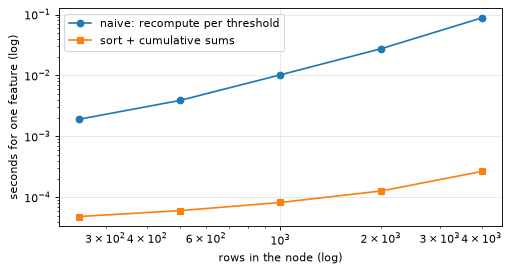

In [5]:
rng = np.random.default_rng(0)
print("    n    naive (s)   sorted (s)   speed-up   same threshold?")
sizes, t_naive, t_fast = [250, 500, 1000, 2000, 4000], [], []
for n in sizes:
    x = rng.uniform(0, 10, n); y = np.sin(x) + rng.normal(0, 0.3, n); w = rng.integers(0, 4, n).astype(float)
    t0 = time.perf_counter(); naive = find_best_split_naive(x, y, w); t_naive.append(time.perf_counter() - t0)
    keep = w > 0
    t0 = time.perf_counter(); fast = find_best_split_mse(x[keep], y[keep], w[keep]); t_fast.append(time.perf_counter() - t0)
    print(f"{n:5d}   {t_naive[-1]:8.4f}    {t_fast[-1]:8.5f}    {t_naive[-1] / t_fast[-1]:6.0f}x    {naive[1] == fast[1]}")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.loglog(sizes, t_naive, "o-", label="naive: recompute per threshold")
ax.loglog(sizes, t_fast, "s-", label="sort + cumulative sums")
ax.set_xlabel("rows in the node (log)"); ax.set_ylabel("seconds for one feature (log)"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Both functions return the same threshold every time, but the naive one gets slower like $n^2$ (its line climbs
>   ~2× per doubling at first, then faster), while sort + cumulative sums stays near-flat. The speed-up grows from
>   roughly 10–50× at 250 rows to several hundred × at 4 000 rows (exact timings vary from run to run).
> * A deep tree runs this search at every node and for every feature, and a bag does it for every tree — so this is
>   *the* cost that matters. scikit-learn does the same sort-and-scan in compiled code.
> * On the README example both find x ≤ 3.5; the sorted version reports the proxy 85.5, and
>   $\sum w y^2 - \text{proxy} = 87 - 85.5 = 1.5$ is exactly the naive SSE.

## 2 · Growing a tree (README §2.1)

Start with all rows (with weight > 0) in one node. Repeatedly: if the node can still be split, find the best
(feature, threshold) over all features, send rows with $x_j \le t$ left and the rest right, and continue on both
children. A node becomes a **leaf** when it has fewer than 2 rows, is already pure (its impurity is ~0), or hits
`max_depth`; the leaf predicts the **weighted mean** of its rows (regression).

The tree is stored as flat NumPy arrays (one entry per node): `feature`, `threshold`, `left`, `right`, `value`
(feature −1 = leaf). Like the user's own tree in `src/fromScratch/decisionTrees/`, the code keeps an **index array** of
the rows in each node rather than copying data.

In [6]:
EPSILON = np.finfo(float).eps


def as_float32(X):
    """scikit-learn trees store X as float32; round the same way so thresholds and comparisons match."""
    return np.asarray(X, dtype=np.float32).astype(np.float64)


def leaf_value(y, w, criterion, n_classes):
    if criterion == "mse":
        return np.sum(w * y) / np.sum(w)                     # weighted mean
    counts = np.bincount(y, weights=w, minlength=n_classes)
    return counts / counts.sum()                              # weighted class shares


def node_impurity(y, w, criterion, n_classes):
    W = w.sum()
    if criterion == "mse":
        return np.sum(w * y * y) / W - (np.sum(w * y) / W) ** 2
    counts = np.bincount(y, weights=w, minlength=n_classes)
    return 1.0 - np.sum(counts ** 2) / W ** 2                # Gini impurity


def fit_tree(X, y, w, criterion="mse", max_depth=None, min_samples_leaf=1, n_classes=None):
    """Grow a CART tree on rows weighted by w (w = bootstrap counts). Returns a dict of flat NumPy arrays."""
    X = as_float32(X)
    find_split = find_best_split_mse if criterion == "mse" else find_best_split_gini
    feature, threshold, left, right, value = [], [], [], [], []
    n_tied_splits = 0
    stack = [(np.flatnonzero(w > 0), 0, -1, False)]          # (rows in node, depth, parent, is_left)
    while stack:
        rows, depth, parent, is_left = stack.pop()
        node = len(feature)
        feature.append(-1); threshold.append(np.nan); left.append(-1); right.append(-1)
        value.append(leaf_value(y[rows], w[rows], criterion, n_classes))
        if parent >= 0:
            (left if is_left else right)[parent] = node
        if ((max_depth is not None and depth >= max_depth) or len(rows) < max(2, 2 * min_samples_leaf)
                or node_impurity(y[rows], w[rows], criterion, n_classes) <= EPSILON):
            continue                                          # leaf
        splits = [find_split(X[rows, j], y[rows], w[rows], min_samples_leaf) for j in range(X.shape[1])]
        proxies = np.array([s[0] for s in splits])
        j = int(np.argmax(proxies))                           # first feature with the best proxy
        if not np.isfinite(proxies[j]):
            continue                                          # no valid split: leaf
        n_tied_splits += int(np.sum(proxies == proxies[j]) > 1)
        go_left = X[rows, j] <= splits[j][1]
        feature[node], threshold[node] = j, splits[j][1]
        stack.append((rows[~go_left], depth + 1, node, False))
        stack.append((rows[go_left], depth + 1, node, True))   # popped first: left child numbered first
    return {"feature": np.array(feature), "threshold": np.array(threshold), "left": np.array(left),
            "right": np.array(right), "value": np.array(value), "n_tied_splits": n_tied_splits}


def apply_tree(tree, X):
    """Leaf index reached by every row of X."""
    X = as_float32(X)
    node = np.zeros(len(X), dtype=int)
    active = tree["feature"][node] >= 0
    while active.any():
        a = np.flatnonzero(active)
        go_left = X[a, tree["feature"][node[a]]] <= tree["threshold"][node[a]]
        node[a] = np.where(go_left, tree["left"][node[a]], tree["right"][node[a]])
        active = tree["feature"][node] >= 0
    return node


def predict_tree(tree, X):
    return tree["value"][apply_tree(tree, X)]


def find_best_split_gini(x, y, w, min_samples_leaf=1):
    """Gini version of find_best_split_mse (section 7). y = integer class labels. Returns (proxy, threshold)."""
    n_classes = int(y.max()) + 1 if len(y) else 1
    order = np.argsort(x, kind="stable")
    xs, ws = x[order], w[order]
    onehot = np.zeros((len(xs), max(n_classes, 2))); onehot[np.arange(len(xs)), y[order]] = ws
    C_left = np.cumsum(onehot, axis=0)[:-1]                    # weighted class counts left of each position
    C_right = onehot.sum(axis=0) - C_left
    W_left = np.cumsum(ws)[:-1]; W_right = ws.sum() - W_left
    n_left = np.arange(1, len(xs))
    valid = ((xs[1:] > xs[:-1] + FEATURE_THRESHOLD)
             & (n_left >= min_samples_leaf) & (len(xs) - n_left >= min_samples_leaf))
    if not valid.any():
        return -np.inf, None
    gini_left = 1.0 - np.sum(C_left ** 2, axis=1) / (W_left * W_left)
    gini_right = 1.0 - np.sum(C_right ** 2, axis=1) / (W_right * W_right)
    proxy = np.where(valid, -W_right * gini_right - W_left * gini_left, -np.inf)   # same formula as scikit-learn
    k = int(np.argmax(proxy))
    return proxy[k], xs[k] / 2.0 + xs[k + 1] / 2.0

**Check:** one tree with random integer weights (0–3) vs `DecisionTreeRegressor().fit(X, y, sample_weight=w)`.

In [7]:
w_check = np.random.default_rng(1).integers(0, 4, len(y_tr)).astype(float)
mine = fit_tree(X_tr, y_tr, w_check)
ref = DecisionTreeRegressor(random_state=0).fit(X_tr, y_tr, sample_weight=w_check)
x_dense = np.linspace(-1, 11, 5001)[:, None]
print("nodes: ours", len(mine["feature"]), " sklearn", ref.tree_.node_count)
print("max |ours - sklearn| on 5001 points in [-1, 11]:", np.abs(predict_tree(mine, x_dense) - ref.predict(x_dense)).max())

nodes: ours 317  sklearn 317
max |ours - sklearn| on 5001 points in [-1, 11]: 0.0


> **Implementation hurdle — thresholds, ties and float32.** Three details decide whether two tree implementations agree
> *exactly*:
> 1. **Midpoint thresholds.** The threshold is halfway between two neighbouring training values, and `x <= t` goes
>    left. A new point between them is sent by that midpoint (a different convention, e.g. "threshold = left value",
>    gives the same training fit but different test predictions).
> 2. **Tied x values.** You cannot split *between* two rows with the same $x$; candidate positions exist only between
>    distinct values.
> 3. **float32.** scikit-learn stores `X` as 32-bit floats. Two values that differ only beyond float32 precision are
>    the *same* value to it.

In [8]:
x_tie = np.array([[1.0], [1.0], [2.0], [3.0]]); y_tie = np.array([0.0, 10.0, 5.0, 5.0]); w1 = np.ones(4)
t_tie = fit_tree(x_tie, y_tie, w1)
print("tied x: thresholds used", t_tie["threshold"][t_tie["feature"] >= 0], "| sklearn",
      DecisionTreeRegressor().fit(x_tie, y_tie).tree_.threshold[:1], "-> the two x = 1 rows share a leaf, value",
      predict_tree(t_tie, [[1.0]]))

x_mid = np.array([[0.0], [1.0]]); y_mid = np.array([0.0, 1.0])
t_mid = fit_tree(x_mid, y_mid, np.ones(2))
print("midpoint: threshold", t_mid["threshold"][0], "| predictions at 0.5 and 0.5000001:", predict_tree(t_mid, [[0.5], [0.5000001]]))

x_f32 = np.array([[1.0], [1.00000001], [2.0]]); y_f32 = np.array([0.0, 1.0, 5.0])
print("float32: distinct in float64?", x_f32[0, 0] != x_f32[1, 0], "| in float32?", np.float32(x_f32[0, 0]) != np.float32(x_f32[1, 0]))
print("    leaves: ours", np.sum(fit_tree(x_f32, y_f32, np.ones(3))["feature"] < 0),
      "| sklearn", DecisionTreeRegressor().fit(x_f32, y_f32).get_n_leaves(), "(3 would need a split between 1.0 and 1.00000001)")

tied x: thresholds used [1.5] | sklearn [1.5] -> the two x = 1 rows share a leaf, value [5.]
midpoint: threshold 0.5 | predictions at 0.5 and 0.5000001: [0. 1.]
float32: distinct in float64? True | in float32? False
    leaves: ours 2 | sklearn 2 (3 would need a split between 1.0 and 1.00000001)


> **How to read this**
> * Our tree and scikit-learn's have the same 317 nodes and give **identical** predictions (max difference 0.0) on
>   5 001 points, including points outside the training range.
> * Tied x: the only threshold is 1.5 (between the distinct values 1 and 2); the two rows at x = 1 can never be
>   separated, so they share a leaf with value 5 (the mean of 0 and 10).
> * Midpoint: the threshold between x = 0 and x = 1 is 0.5; a point exactly at 0.5 goes left (prediction 0), a point
>   at 0.5000001 goes right (1).
> * float32: 1.0 and 1.00000001 differ in 64-bit floats but not in 32-bit ones, so both trees see only two distinct
>   values and make 2 leaves. Without the float32 rounding our tree would make 3 leaves and disagree with
>   scikit-learn.

## 3 · Bootstrap samples as counts (README §2.3)

A bootstrap sample draws $n$ row numbers **with replacement**. Instead of copying rows, store **how many times each
row was drawn** — a vector of $n$ small integers, mostly 0, 1 and 2. That vector is exactly the `sample_weight` a tree
gets. Rows with count 0 are the tree's **out-of-bag (OOB)** rows.

In [9]:
def bootstrap_counts(n, n_draws, rng):
    """Draw n_draws row numbers with replacement; return how many times each of the n rows was drawn."""
    return np.bincount(rng.integers(0, n, n_draws), minlength=n)


rng = np.random.default_rng(0)
c = bootstrap_counts(200, 200, rng)
print("first 20 counts:", c[:20])
print("how many rows were drawn 0, 1, 2, 3, 4+ times:", [int(np.sum(c == k)) for k in range(4)] + [int(np.sum(c >= 4))])
shares = [np.mean(bootstrap_counts(200, 200, rng) > 0) for _ in range(2000)]
print(f"share of distinct rows over 2000 samples: {np.mean(shares):.4f}  (formula 1-(1-1/200)^200 = {1 - (1 - 1 / 200) ** 200:.4f})")

first 20 counts: [1 2 1 2 1 1 1 0 1 3 1 1 0 0 1 3 3 1 1 0]
how many rows were drawn 0, 1, 2, 3, 4+ times: [69, 83, 30, 16, 2]
share of distinct rows over 2000 samples: 0.6335  (formula 1-(1-1/200)^200 = 0.6330)


> **Implementation hurdle — weights vs duplicated rows.** Fitting on the duplicated rows (`X[rows]`) or on all rows
> with counts as weights gives the **same** tree, because every sum in section 1 counts a row $w_i$ times either way —
> and the counts version needs no copy of `X`. **But** rules that count *rows*, such as `min_samples_leaf`, see
> different numbers: with weights a leaf of 3 distinct rows drawn twice each has 3 rows, with duplicates it has 6.
> scikit-learn behaves the same way, and `BaggingRegressor` uses the weights route — so inside a bag,
> `min_samples_leaf` counts **distinct** rows.

In [10]:
rows = np.random.default_rng(3).integers(0, len(y_tr), len(y_tr))
counts = np.bincount(rows, minlength=len(y_tr)).astype(float)
for msl in [1, 5]:
    ours_w = predict_tree(fit_tree(X_tr, y_tr, counts, min_samples_leaf=msl), x_dense)
    ours_d = predict_tree(fit_tree(X_tr[rows], y_tr[rows], np.ones(len(rows)), min_samples_leaf=msl), x_dense)
    sk_w = DecisionTreeRegressor(min_samples_leaf=msl).fit(X_tr, y_tr, sample_weight=counts).predict(x_dense)
    sk_d = DecisionTreeRegressor(min_samples_leaf=msl).fit(X_tr[rows], y_tr[rows]).predict(x_dense)
    print(f"min_samples_leaf={msl}: weights vs duplicates -> ours max diff {np.abs(ours_w - ours_d).max():.3g}, "
          f"sklearn max diff {np.abs(sk_w - sk_d).max():.3g};  ours vs sklearn: weights {np.abs(ours_w - sk_w).max():.3g}, "
          f"duplicates {np.abs(ours_d - sk_d).max():.3g}")
for p in [1, 50]:                                         # memory for one bootstrap sample of 200 rows
    print(f"{p:2d} column(s): count vector {len(y_tr) * 8:6d} bytes   vs   copied rows {len(rows) * p * 8:6d} bytes")

min_samples_leaf=1: weights vs duplicates -> ours max diff 0, sklearn max diff 0;  ours vs sklearn: weights 0, duplicates 0
min_samples_leaf=5: weights vs duplicates -> ours max diff 0.778, sklearn max diff 0.778;  ours vs sklearn: weights 2.22e-16, duplicates 1.11e-16
 1 column(s): count vector   1600 bytes   vs   copied rows   1600 bytes
50 column(s): count vector   1600 bytes   vs   copied rows  80000 bytes


> **How to read this**
> * Of 200 rows, 69 were never drawn (34.5 %), 83 once, 30 twice, 16 three times and 2 four or more times. Over 2 000
>   samples the share of distinct rows is 0.6335 (formula 0.6330).
> * With `min_samples_leaf=1`, counts and duplicated rows give identical trees, in our code and in scikit-learn
>   (difference 0). With `min_samples_leaf=5` they differ by up to 0.778 — **in both libraries alike**, and ours
>   matches scikit-learn to 2e-16 either way. The rule counts rows, and "rows" means distinct rows when you pass
>   weights.
> * The count vector costs 8 bytes per training row no matter how many columns; copying the drawn rows costs 8 bytes
>   per row **per column** (1 600 vs 80 000 bytes with 50 columns).

## 4 · The hand-worked example (README §5)

Six rows, three bootstrap samples, a stump (`max_depth=1`) per sample, the average, and the OOB predictions.

In [11]:
X_toy = x_toy[:, None]
samples_toy = [np.array([1, 1, 4, 4, 5, 5]), np.array([2, 2, 3, 3, 4, 6]), np.array([1, 1, 3, 3, 5, 5])]
counts_toy = [np.bincount(s - 1, minlength=6).astype(float) for s in samples_toy]
stumps_toy = [fit_tree(X_toy, y_toy, c, max_depth=1) for c in counts_toy]
for b, (s, t) in enumerate(zip(samples_toy, stumps_toy), start=1):
    print(f"stump {b}: x <= {t['threshold'][0]}  left leaf {t['value'][1]:.2f}  right leaf {t['value'][2]:.2f}")
P_toy = np.array([predict_tree(t, X_toy) for t in stumps_toy])
oob_mask_toy = np.array(counts_toy) == 0
print("bag prediction rows 1..6:", P_toy.mean(axis=0))
print("bag prediction at x = 3:", np.mean([predict_tree(t, [[3.0]])[0] for t in stumps_toy]))
print("OOB prediction rows 1..6:", (P_toy * oob_mask_toy).sum(axis=0) / oob_mask_toy.sum(axis=0))
assert np.allclose(P_toy.mean(axis=0), [5 / 3, 5 / 3, 3.5, 4.5, 19 / 3, 19 / 3])

stump 1: x <= 2.5  left leaf 1.00  right leaf 6.50
stump 2: x <= 3.5  left leaf 2.50  right leaf 5.50
stump 3: x <= 4.0  left leaf 1.50  right leaf 7.00
bag prediction rows 1..6: [1.667 1.667 3.5   4.5   6.333 6.333]
bag prediction at x = 3: 3.5
OOB prediction rows 1..6: [2.5  1.25 6.5  1.5  5.5  6.75]


> **How to read this**
> * Same thresholds and leaves as README §5 (2.5: 1 | 6.5; 3.5: 2.5 | 5.5; 4.0: 1.5 | 7), the same bag predictions
>   (1.667, 1.667, 3.5, 4.5, 6.333, 6.333; 3.5 at x = 3) and the same OOB predictions (2.5, 1.25, 6.5, 1.5, 5.5, 6.75).

## 5 · Bagging = many trees on many bootstrap samples, averaged (README §3)

$$\hat f_{\text{bag}}(x) = \frac{1}{B}\sum_{b=1}^{B} \hat f_b(x), \qquad \hat f_b = \text{tree fitted with the counts of bootstrap sample } b.$$

To check **exactness**, we do not draw our own samples here: we take scikit-learn's own draws
(`BaggingRegressor.estimators_samples_`, one array of drawn row numbers per tree), turn them into counts with
`np.bincount` (exactly what scikit-learn does internally before calling the tree's `fit` with `sample_weight`), fit
our trees with them, and compare tree by tree.

In [12]:
def fit_bagging(X, y, counts_per_tree, **tree_params):
    """One tree per count vector. The ensemble is just the list of trees."""
    return [fit_tree(X, y, c.astype(float), **tree_params) for c in counts_per_tree]


def predict_bagging(trees, X):
    return np.mean([predict_tree(t, X) for t in trees], axis=0)


def counts_from_sklearn(bag, n_rows):
    return [np.bincount(s, minlength=n_rows) for s in bag.estimators_samples_]


sk_bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, oob_score=True, random_state=0).fit(X_tr, y_tr)
counts_sk = counts_from_sklearn(sk_bag, len(y_tr))
our_trees = fit_bagging(X_tr, y_tr, counts_sk)
per_tree_diff = max(np.abs(predict_tree(t, x_dense) - est.predict(x_dense)).max() for t, est in zip(our_trees, sk_bag.estimators_))
print("largest per-tree difference over 100 trees x 5001 points:", per_tree_diff)
print("ensemble: max |ours - sklearn| on the dense grid:", np.abs(predict_bagging(our_trees, x_dense) - sk_bag.predict(x_dense)).max())
print("ensemble: max |ours - sklearn| on the test rows :", np.abs(predict_bagging(our_trees, X_te) - sk_bag.predict(X_te)).max())

largest per-tree difference over 100 trees x 5001 points: 0.0
ensemble: max |ours - sklearn| on the dense grid: 0.0
ensemble: max |ours - sklearn| on the test rows : 0.0


> **How to read this**
> * Fed scikit-learn's own bootstrap draws, our 100 trees reproduce scikit-learn's 100 trees **exactly**: the
>   largest difference over 100 trees × 5 001 points is 0.0, and so is the ensemble's.
> * This works because (1) `BaggingRegressor` gives each tree `sample_weight = np.bincount(draws)`, which is exactly our
>   count vector; (2) our split search, midpoint thresholds, float32 rounding and leaf rule copy scikit-learn's; and
>   (3) with one feature there is never a tie between features (section 7).

## 6 · Out-of-bag predictions (README §4.6)

For training row $i$, average only the trees whose bootstrap sample did **not** contain it:

$$\hat f_{\text{OOB}}(x_i) = \frac{1}{|\{b : c_{bi} = 0\}|}\sum_{b:\, c_{bi} = 0} \hat f_b(x_i), \qquad
\text{OOB } R^2 = 1 - \frac{\sum_i (y_i - \hat f_{\text{OOB}}(x_i))^2}{\sum_i (y_i - \bar y)^2}.$$

In [13]:
def oob_predictions(trees, counts_per_tree, X):
    """Average over the trees that did not see each row. NaN where every tree saw the row."""
    preds = np.array([predict_tree(t, X) for t in trees])         # B x n (regression) or B x n x K (classes)
    oob = (np.array(counts_per_tree) == 0).astype(float)          # B x n: 1 where tree b did not see row i
    weights = oob.reshape(oob.shape + (1,) * (preds.ndim - 2))    # broadcast over the class axis, if any
    with np.errstate(invalid="ignore", divide="ignore"):
        return (preds * weights).sum(axis=0) / weights.sum(axis=0), oob.sum(axis=0)


def r2(y, pred):
    return 1.0 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)


oob_pred, n_oob = oob_predictions(our_trees, counts_sk, X_tr)
print("max |our OOB prediction - sklearn oob_prediction_|:", np.abs(oob_pred - sk_bag.oob_prediction_).max())
print(f"OOB R^2: ours {r2(y_tr, oob_pred):.12f}   sklearn {sk_bag.oob_score_:.12f}")

max |our OOB prediction - sklearn oob_prediction_|: 0.0
OOB R^2: ours 0.752116445196   sklearn 0.752116445196


> **Implementation hurdle — rows with no OOB tree.** A row drawn by *every* tree has no OOB prediction. With $B$ trees
> that happens with probability $0.632^B$ — 25 % of rows for $B = 3$, about $10^{-20}$ for $B = 100$. scikit-learn
> warns and fills those rows with **0**, which drags `oob_score_` down; our function returns `NaN` so the caller must
> decide (here: leave those rows out).

In [14]:
with warnings.catch_warnings(record=True) as caught:      # the warning is the lesson
    warnings.simplefilter("always")
    sk_bag3 = BaggingRegressor(DecisionTreeRegressor(), n_estimators=3, oob_score=True, random_state=0).fit(X_tr, y_tr)
print("sklearn warning:", [str(w.message) for w in caught])
counts3 = counts_from_sklearn(sk_bag3, len(y_tr))
oob3, n_oob3 = oob_predictions(fit_bagging(X_tr, y_tr, counts3), counts3, X_tr)
has = n_oob3 > 0
print(f"rows without an OOB tree: {np.sum(~has)} of {len(y_tr)} (expected 0.632^3 = {0.632 ** 3:.1%})")
print(f"sklearn oob_score_ (those rows predicted as 0): {sk_bag3.oob_score_:.4f}")
print(f"ours, same convention (NaN -> 0)              : {r2(y_tr, np.nan_to_num(oob3)):.4f}")
print(f"ours, rows with an OOB tree only              : {r2(y_tr[has], oob3[has]):.4f}")

sklearn warning: ['Some inputs do not have OOB scores. This probably means too few estimators were used to compute any reliable oob estimates.']
rows without an OOB tree: 54 of 200 (expected 0.632^3 = 25.2%)
sklearn oob_score_ (those rows predicted as 0): 0.4582
ours, same convention (NaN -> 0)              : 0.4582
ours, rows with an OOB tree only              : 0.6451


> **How to read this**
> * Our OOB predictions equal `oob_prediction_` exactly and the OOB R² agrees to 12 decimals (0.752116445196).
> * With 3 trees, 54 of 200 rows have no OOB tree (≈ 25 % expected). Using scikit-learn's convention (predict 0) we
>   reproduce its 0.4582; dropping those rows gives 0.6451. The 0-filling, not the model, causes the low score.

## 7 · Classification: a Gini tree with weights, soft voting (README §2.1, §3)

A classification tree measures how mixed a node is with the **Gini impurity** $1 - \sum_k p_k^2$ ($p_k$ = weighted
share of class $k$). The split search is the same sort + cumulative-sum trick, with cumulative **class counts**
(`find_best_split_gini`, defined in section 2). A leaf stores the class shares; the bag averages them (soft voting,
which is what `BaggingClassifier` does when its trees have `predict_proba`).

Two datasets: a **1-D** one (good-fit `x`, label = "is y > 0?") and the **2-D** `make_moons`.

In [15]:
yc_tr = (y_tr > 0).astype(int)
moons_X, moons_y = make_moons(n_samples=300, noise=0.3, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(moons_X, moons_y, test_size=1 / 3, random_state=0)

for name, Xc, yc, Xc_test in [("1-D (good-fit x, y > 0)", X_tr, yc_tr, x_dense), ("2-D moons", Xm_tr, ym_tr, Xm_te)]:
    sk_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=0).fit(Xc, yc)
    counts_c = counts_from_sklearn(sk_clf, len(yc))
    trees_c = fit_bagging(Xc, yc, counts_c, criterion="gini", n_classes=2)
    inbag_diff = max(np.abs(predict_tree(t, Xc[c > 0]) - est.predict_proba(Xc[c > 0])).max()
                     for t, c, est in zip(trees_c, counts_c, sk_clf.estimators_))
    test_diff = max(np.abs(predict_tree(t, Xc_test) - est.predict_proba(Xc_test)).max() for t, est in zip(trees_c, sk_clf.estimators_))
    proba = predict_bagging(trees_c, Xc_test)
    oob_c, _ = oob_predictions(trees_c, counts_c, Xc)
    print(f"{name}:")
    print(f"    splits where two features tie for best: {sum(t['n_tied_splits'] for t in trees_c)} (over 100 trees)")
    print(f"    per-tree max |proba diff|: in-bag rows {inbag_diff:.3g}, new points {test_diff:.3g}")
    print(f"    ensemble: max |proba diff| {np.abs(proba - sk_clf.predict_proba(Xc_test)).max():.3g}, "
          f"identical class predictions {np.mean(proba.argmax(axis=1) == sk_clf.predict(Xc_test)):.1%}")
    print(f"    OOB accuracy: ours {accuracy_score(yc, oob_c.argmax(axis=1)):.4f}, sklearn {sk_clf.oob_score_:.4f}")
    if Xc_test is Xm_te:
        print(f"    test accuracy: ours {accuracy_score(ym_te, proba.argmax(axis=1)):.4f}, sklearn {accuracy_score(ym_te, sk_clf.predict(Xm_te)):.4f}")

1-D (good-fit x, y > 0):
    splits where two features tie for best: 0 (over 100 trees)
    per-tree max |proba diff|: in-bag rows 0, new points 0


    ensemble: max |proba diff| 0, identical class predictions 100.0%
    OOB accuracy: ours 0.9100, sklearn 0.9100
2-D moons:
    splits where two features tie for best: 197 (over 100 trees)
    per-tree max |proba diff|: in-bag rows 0, new points 1
    ensemble: max |proba diff| 0.08, identical class predictions 100.0%
    OOB accuracy: ours 0.9250, sklearn 0.9250
    test accuracy: ours 0.9300, sklearn 0.9300


> **Implementation hurdle — ties between features.** When two features give exactly the same best proxy (common in
> small nodes: with 2 rows of different classes, *any* feature that separates them is perfect), something must break
> the tie. We take the lowest feature number; scikit-learn visits the features in a **random order** (from the tree's
> `random_state`) and keeps the first best. Both choices send the *training* rows to the same leaves, but they use
> different thresholds on different features, so **new** points can land differently. With one feature there are no
> ties and the match is exact.

> **How to read this**
> * 1-D: no ties are possible, and the Gini trees match scikit-learn exactly — per-tree differences 0, ensemble
>   probabilities identical, OOB accuracy 0.9100 on both sides.
> * 2-D moons: 197 splits (over 100 trees) had two equally good features. Training rows still land in identical leaves
>   (in-bag difference 0), but on new points a single tree can flip a whole leaf (difference 1). Averaged over 100
>   trees the probabilities differ by at most 0.08, every predicted class is identical, and OOB (0.9250) and test
>   (0.9300) accuracy are equal.

## 8 · Implementation hurdle — time and memory grow linearly with $B$

Every tree is fitted and stored separately, so fitting time, prediction time and the number of stored nodes all grow
in proportion to $B$ (README §8). Our pure-NumPy loop is slower than scikit-learn's compiled trees by a constant
factor, but the *shape* is the same.

In [16]:
rng = np.random.default_rng(0)
print("    B   ours fit (s)   sklearn fit (s)   ours nodes   ours predict 5001 pts (s)")
for B in [10, 50, 200]:
    counts_B = [bootstrap_counts(len(y_tr), len(y_tr), rng) for _ in range(B)]
    t0 = time.perf_counter(); trees_B = fit_bagging(X_tr, y_tr, counts_B); t_ours = time.perf_counter() - t0
    t0 = time.perf_counter(); BaggingRegressor(DecisionTreeRegressor(), n_estimators=B, random_state=0).fit(X_tr, y_tr); t_sk = time.perf_counter() - t0
    t0 = time.perf_counter(); predict_bagging(trees_B, x_dense); t_pred = time.perf_counter() - t0
    print(f"{B:5d}   {t_ours:9.3f}      {t_sk:9.3f}        {sum(len(t['feature']) for t in trees_B):7d}       {t_pred:8.3f}")

    B   ours fit (s)   sklearn fit (s)   ours nodes   ours predict 5001 pts (s)


   10       0.037          0.005           2498          0.004


   50       0.158          0.022          12636          0.022


  200       0.626          0.086          50602          0.084


> **How to read this**
> * All three columns grow roughly in proportion to B: about 2 500, 12 600 and 50 600 stored nodes for B = 10, 50 and
>   200, and fit/predict times scale the same way.
> * Our NumPy trees fit several times slower than scikit-learn's compiled ones (exact ratios vary between runs); the
>   algorithm and its linear cost in B are the same.

## 9 · Final comparison with scikit-learn on both CSVs

Same hyper-parameters on both sides: 100 deep trees, bootstrap rows, all features, `random_state=0` for scikit-learn.

* **ours (sklearn draws)** — our trees fitted with scikit-learn's bootstrap counts: should match to the last digit.
* **ours (own draws)** — our own `bootstrap_counts` with NumPy's generator: a *different* random sample, so numbers
  differ slightly; only the metrics should be close.

In [17]:
def compare_on(name, Xa, ya, Xb, yb):
    t0 = time.perf_counter()
    sk = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, oob_score=True, random_state=0).fit(Xa, ya)
    t_sk = time.perf_counter() - t0
    counts_a = counts_from_sklearn(sk, len(ya))
    t0 = time.perf_counter(); trees_a = fit_bagging(Xa, ya, counts_a); t_a = time.perf_counter() - t0
    rng = np.random.default_rng(0)
    counts_b = [bootstrap_counts(len(ya), len(ya), rng) for _ in range(100)]
    t0 = time.perf_counter(); trees_b = fit_bagging(Xa, ya, counts_b); t_b = time.perf_counter() - t0
    rows = []
    for label, trees, counts, t_fit, pred in [("sklearn", None, None, t_sk, sk.predict(Xb)),
                                               ("ours (sklearn draws)", trees_a, counts_a, t_a, predict_bagging(trees_a, Xb)),
                                               ("ours (own draws)", trees_b, counts_b, t_b, predict_bagging(trees_b, Xb))]:
        oob = sk.oob_score_ if trees is None else r2(ya, oob_predictions(trees, counts, Xa)[0])
        rows.append((label, mean_squared_error(yb, pred), oob, np.abs(pred - sk.predict(Xb)).max(), t_fit))
    print(f"\n{name}")
    print("  model                  test MSE    OOB R^2      max |pred - sklearn|   fit time (s)")
    for label, mse, oob, diff, t_fit in rows:
        print(f"  {label:22s} {mse:9.5f}   {oob:.6f}     {diff:10.3g}           {t_fit:6.3f}")


compare_on("good fit (200 train / 100 test)", X_tr, y_tr, X_te, y_te)
compare_on("bad fit (train x < 6, test x >= 6: extrapolation)", Xb_tr, yb_tr, Xb_te, yb_te)


good fit (200 train / 100 test)
  model                  test MSE    OOB R^2      max |pred - sklearn|   fit time (s)
  sklearn                  0.18513   0.752116              0            0.053
  ours (sklearn draws)     0.18513   0.752116              0            0.311
  ours (own draws)         0.18727   0.748451          0.119            0.308



bad fit (train x < 6, test x >= 6: extrapolation)
  model                  test MSE    OOB R^2      max |pred - sklearn|   fit time (s)
  sklearn                  4.72735   0.844223              0            0.050
  ours (sklearn draws)     4.72735   0.844223              0            0.171
  ours (own draws)         4.97003   0.844372         0.0619            0.171


> **How to read this**
> * Good fit: our bag with scikit-learn's draws equals scikit-learn to the last digit — test MSE 0.18513, OOB R²
>   0.752116, max prediction difference 0. With our own random draws the trees differ (max difference 0.119), yet the
>   metrics are close (0.18727, 0.748451): a different but equally good random bag.
> * Bad fit: again an exact match (test MSE 4.72735, OOB R² 0.844223). The high OOB R² (0.84) next to the large test
>   error is the extrapolation failure: OOB rows lie *inside* the training range, so OOB cannot warn you that the test
>   rows lie outside it.
> * Fit time: our pure-NumPy version is slower than scikit-learn (see the last column; it varies between runs).

---
# Summary — what each section showed

| Section | Claim | Verdict |
|---|---|---|
| 1 | Sort + cumulative sums finds the same split as the naive search, hundreds of times faster at 4 000 rows | ✔ |
| 2 | Our weighted CART tree = `DecisionTreeRegressor` (midpoints, ties, float32) | ✔ exact (0.0) |
| 3 | Bootstrap = count vector; ≈ 63.3 % distinct rows; counts ≡ duplicated rows except for row-count rules | ✔ |
| 4 | README §5 hand example | ✔ same numbers |
| 5 | Our bag with scikit-learn's draws = `BaggingRegressor`, tree by tree | ✔ exact (0.0) |
| 6 | Our OOB predictions and R² = `oob_prediction_`, `oob_score_`; rows without OOB trees handled | ✔ exact |
| 7 | Gini trees + soft vote = `BaggingClassifier` (exact in 1-D; in 2-D same classes, tie-broken thresholds differ) | ✔ |
| 8 | Cost grows linearly with B | ✔ |
| 9 | Both CSVs: identical metrics with the same draws; close metrics with our own draws | ✔ |